In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from itertools import product
from matplotlib.lines import Line2D
import math
from scipy.linalg import expm
from joblib import Parallel, delayed




# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# DGR
It shouldn't change anything, the most important path goes from dominant sequence to another

## L=2

In [2]:
def compete_4x4_multinomial(
    tau,  nu, s,dt,
    PopSize=10**8,
    steps=1000
):

    # --- helper lists for decoding/encoding ---
    VR_pairs = [(i, j) for i in range(4) for j in range(4)]  # length 16

    # --- initialize population evenly across 256 TRxVR cells ---
    Pop = np.zeros( 16, dtype=np.int64)
    base_each = PopSize // 16
    if base_each > 0:
        Pop[:] = base_each
    leftover = PopSize - Pop.sum()
    # give leftover to cell (0,0)
    if leftover > 0:
        Pop[0, 0] += leftover

    # --- fixed 9-state environment cycle as requested ---
    env_cycle_pairs = [
        (0,0),(1,1), (2,2), (3,3)
    ]
    # create Hcycle: each H is length-16 vector with additive contribution
    Hcycle = []
    for (E1, E2) in env_cycle_pairs:
        h = np.zeros(16, dtype=float)
        for idx, (x, y) in enumerate(VR_pairs):
            h[idx] =  s*(1 if x == E1 else 0)*(1 if y == E2 else 0)
        Hcycle.append(h)

    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    freqVR = []
    AvH = []

    for k in range(steps):
        # ---- environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # ---- SELECTION / REPRODUCTION ----
        # growth factors per VR type
        w = np.exp(H * dt)              # shape (16,)
        weighted = Pop * w[ :]     # broadcast to (16,16)
        total_fit = weighted.sum()
        if total_fit <= 0:
            P_repro = np.ones(16, dtype=float) / 256.0
        else:
            P_repro = weighted / total_fit

        new_counts = np.random.multinomial(PopSize, P_repro.reshape(-1))
        Pop = new_counts[:]

        # ---- VR SWITCHING per TR rules (four cases) ----
        if nu * dt > 0:
                S=0
                for vr in range(16):
                    count = Pop[ vr]
                    if count == 0:
                        continue
                    s = np.random.binomial(count, nu * dt)
                    if s == 0:
                        continue
                    Pop[vr] -= s
                    S+=s
                Pop[:] += np.random.multinomial(S, [1/16.0] * 16)

        # ---- statistics ----
        freqVR.append(Pop.astype(float) / PopSize)
        AvH.append(np.sum(Pop * H[ :]) / PopSize)

    # discard initial transient of 3 environment periods
    cut = 3 * int(tau / dt)
    freqVR = np.array(freqVR)
    AvH = np.array(AvH)


    return  np.mean(AvH[cut:])


In [3]:
import numpy as np
from joblib import Parallel, delayed


# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list( 
    tau, nu_list,s, dt,
    PopSize=10**8,
    steps=1000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_16x16_multinomial)(tau, nu,s, dt,
    PopSize,
    steps) for nu in nu_list
    )
    return results

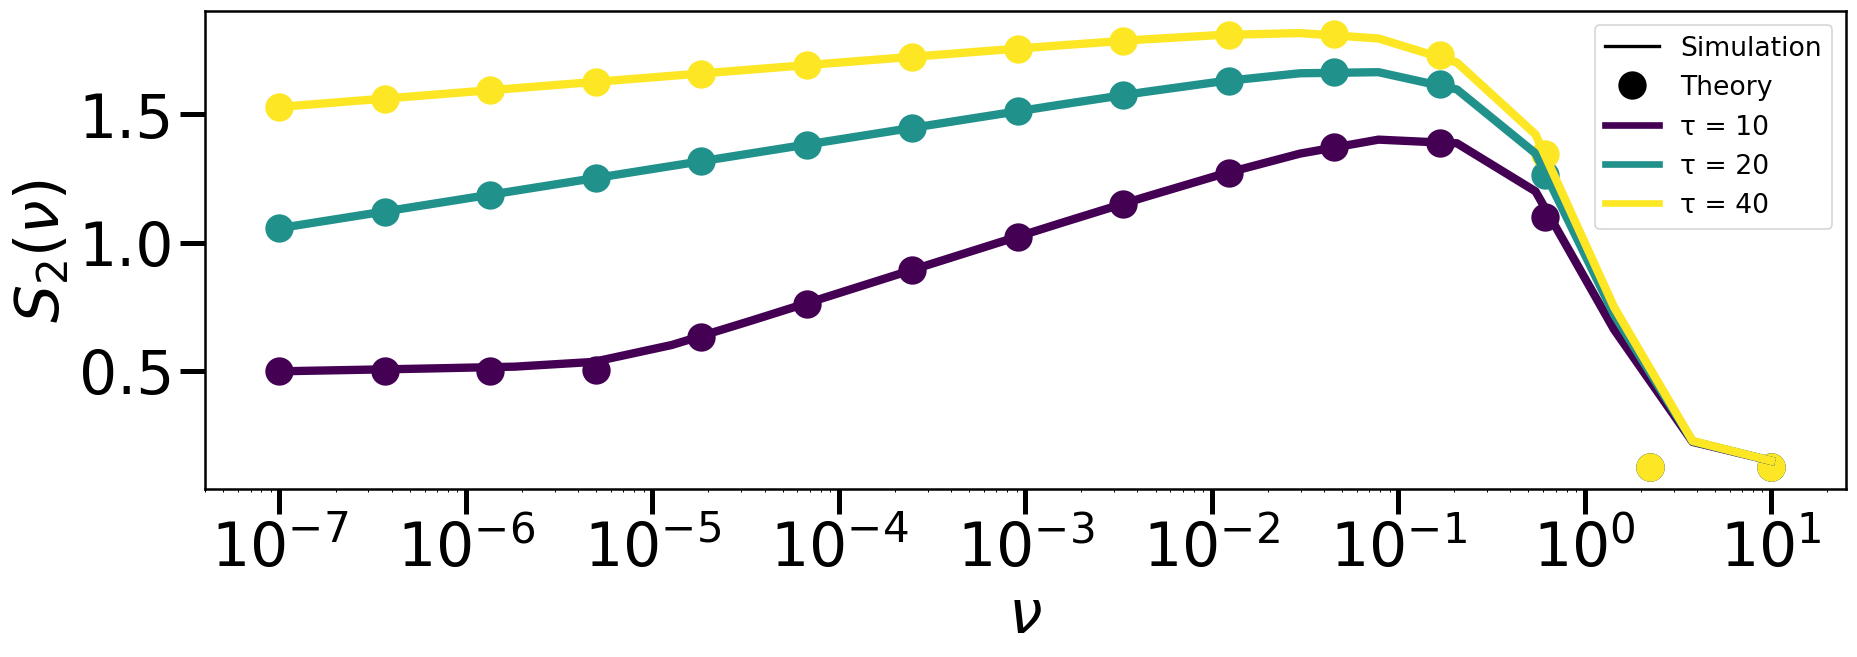

In [4]:
# === Parameters ===
Q = 4
L=2
s=2
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [10, 20,40]
dt=1e-2
PopSize=10**15
mu_list = np.logspace(-7, 1, 100)  # equivalent to ν in your Mathematica code
nu_list=np.logspace(-7,1,20)
# === Compute theory curves ===
theory_data = {}
for tau in taus:
    theory_data[tau] = [
        max(s/Q, s - mu*(1 - Q**(-L)) + np.log(2*mu/Q**L/s)/tau) if mu < 1
        else max(s/Q**L, s - mu*(1 - Q**(-L)) + np.log(2*mu/Q**L/s)/tau)
        for mu in mu_list
    ]
# === Optional: save to CSV to compare with simulation ===
df_list = []
for tau in taus:
    for mu, r in zip(mu_list, theory_data[tau]):
        df_list.append([tau, mu, r])
df_theory = pd.DataFrame(df_list, columns=["tau", "nu", "rInf"])
df_theory.to_csv("growth_data.csv", index=False)

# === Load simulation results (replace with your own growth_for_nu_list function) ===
# from your previous Monte Carlo simulations
# results_sim = growth_for_nu_list(Q, tau, mu_list, dt, PopSize)

# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    results = growth_for_nu_list(tau, nu_list, s,dt,
    PopSize,
    steps=20000)  # your stochastic sim
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    idx = np.linspace(0, len(mu_list)-1, min(15, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_2(\nu)$")
plt.xscale("log")
plt.tight_layout()
plt.savefig('Effective_Growth_VR_epistatic_L2.svg')
plt.show()

## L=4

In [5]:
def compete_256_multinomial(
    tau,  nu,s, dt,
    PopSize=10**8,
    steps=1000
):
    

    # --- helper lists for decoding/encoding ---
    VR_pairs = [(i, j,k,l) for i in range(4) for j in range(4) for k in range(4) for l in range(4)]  # length 16

    # --- initialize population evenly across 256 TRxVR cells ---
    Pop = np.zeros( 256, dtype=np.int64)
    base_each = PopSize // 256
    if base_each > 0:
        Pop[:] = base_each
    leftover = PopSize - Pop.sum()
    # give leftover to cell (0,0)
    if leftover > 0:
        Pop[0, 0] += leftover

    # --- fixed 9-state environment cycle as requested ---
    env_cycle_pairs = [
        (0,0,0,0),(1,1,1,1), (2,2,2,2), (3,3,3,3)
    ]
    # create Hcycle: each H is length-16 vector with additive contribution
    Hcycle = []
    for (E1, E2,E3,E4) in env_cycle_pairs:
        h = np.zeros(256, dtype=float)
        for idx, (x, y,z,w) in enumerate(VR_pairs):
            h[idx] =  s*(1 if x == E1 else 0)*(1 if y == E2 else 0)*(1 if z == E3 else 0)*(1 if w == E3 else 0)
        Hcycle.append(h)

    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    freqVR = []
    AvH = []

    for k in range(steps):
        # ---- environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # ---- SELECTION / REPRODUCTION ----
        # growth factors per VR type
        w = np.exp(H * dt)              # shape (16,)
        weighted = Pop * w[ :]     # broadcast to (16,16)
        total_fit = weighted.sum()
        if total_fit <= 0:
            P_repro = np.ones(256, dtype=float) / 256.0
        else:
            P_repro = weighted / total_fit

        new_counts = np.random.multinomial(PopSize, P_repro.reshape(-1))
        Pop = new_counts[:]

        # ---- VR SWITCHING per TR rules (four cases) ----
        if nu * dt > 0:
                S=0
                for vr in range(256):
                    count = Pop[ vr]
                    if count == 0:
                        continue
                    s = np.random.binomial(count, nu * dt)
                    if s == 0:
                        continue
                    Pop[vr] -= s
                    S+=s
                Pop[:] += np.random.multinomial(S, [1/256.0] * 256)

        # ---- statistics ----
        freqVR.append(Pop.astype(float) / PopSize)
        AvH.append(np.sum(Pop * H[ :]) / PopSize)

    # discard initial transient of 3 environment periods
    cut = 3 * int(tau / dt)
    freqVR = np.array(freqVR)
    AvH = np.array(AvH)


    return  np.mean(AvH[cut:])


In [6]:
import numpy as np
from joblib import Parallel, delayed


# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list( 
    tau, nu_list, s,dt,
    PopSize=10**8,
    steps=1000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_256_multinomial)(tau, nu, s,dt,
    PopSize,
    steps) for nu in nu_list
    )
    return results

10
20
40


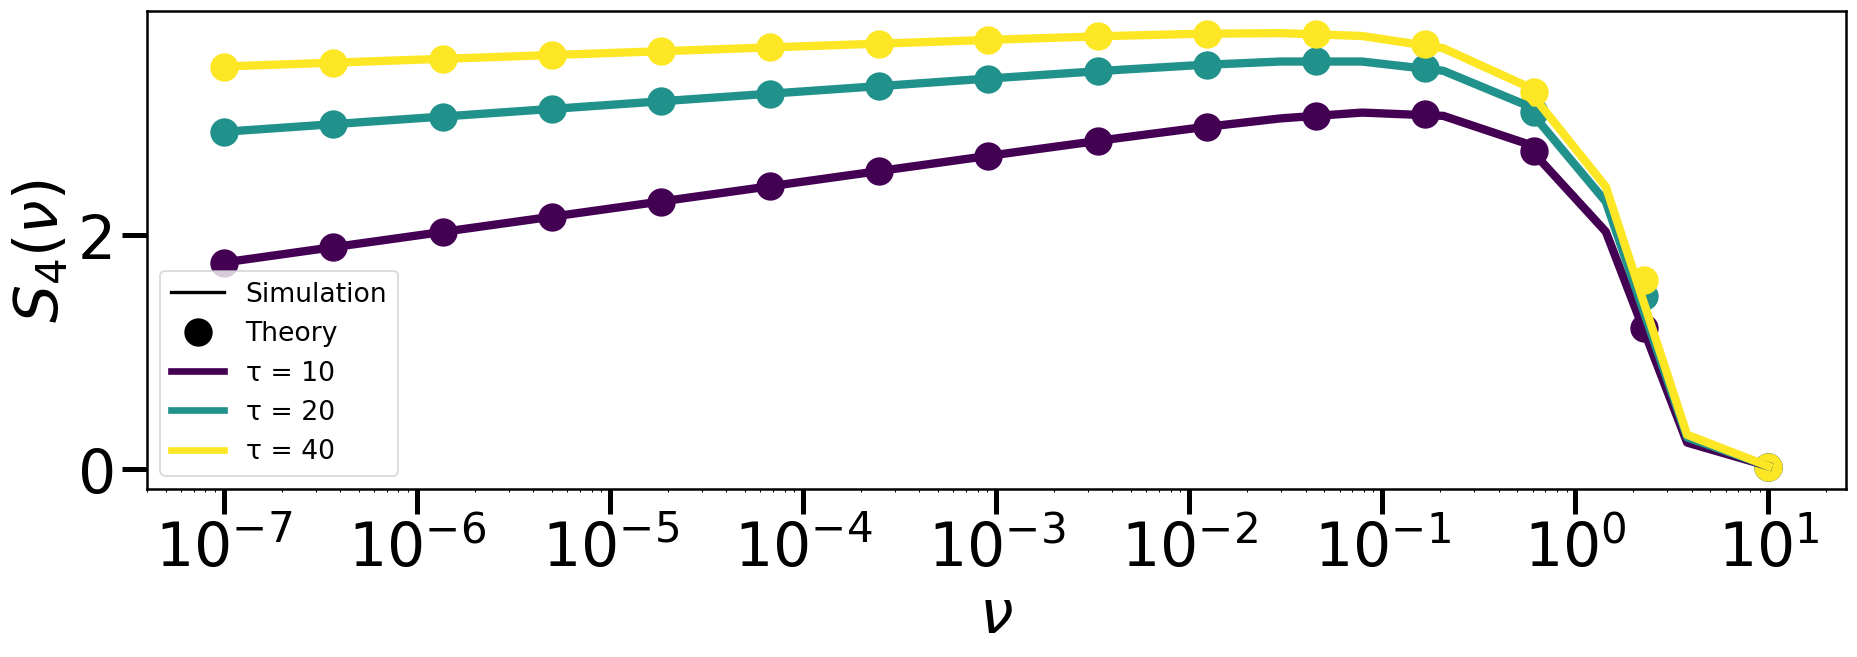

In [7]:
# === Parameters ===
Q = 4
L=4
s=4
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [10, 20,40]
dt=1e-2
PopSize=10**15
mu_list = np.logspace(-7, 1, 100)  # equivalent to ν in your Mathematica code
nu_list=np.logspace(-7,1,20)
# === Compute theory curves ===
theory_data = {}
for tau in taus:
    theory_data[tau] = [
        max(s/Q, s - mu*(1 - Q**(-L)) + np.log(2*mu/Q**L/s)/tau) if mu < 1
        else max(s/Q**L, s - mu*(1 - Q**(-L)) + np.log(2*mu/Q**L/s)/tau)
        for mu in mu_list
    ]
# === Optional: save to CSV to compare with simulation ===
df_list = []
for tau in taus:
    for mu, r in zip(mu_list, theory_data[tau]):
        df_list.append([tau, mu, r])
df_theory = pd.DataFrame(df_list, columns=["tau", "nu", "rInf"])
df_theory.to_csv("growth_data.csv", index=False)

# === Load simulation results (replace with your own growth_for_nu_list function) ===
# from your previous Monte Carlo simulations
# results_sim = growth_for_nu_list(Q, tau, mu_list, dt, PopSize)

# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    print(tau)
    results = growth_for_nu_list(tau, nu_list,s, dt,
    PopSize,
    steps=20000)  # your stochastic sim
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    idx = np.linspace(0, len(mu_list)-1, min(15, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_4(\nu)$")
plt.xscale("log")
plt.tight_layout()
plt.savefig('Effective_Growth_VR_epistatic_L4.svg')
plt.show()

# Point mutation 

## L=2

In [8]:
def compete_4x4_multinomial(
    tau,  nu, s,dt,
    PopSize=10**8,
    steps=1000
):

    # --- helper lists for decoding/encoding ---
    VR_pairs = [(i, j) for i in range(4) for j in range(4)]  # length 16

    # --- initialize population evenly across 256 TRxVR cells ---
    Pop = np.zeros(16, dtype=np.int64)
    base_each = PopSize // 16
    if base_each > 0:
        Pop[:] = base_each
    leftover = PopSize - Pop.sum()
    # give leftover to cell (0,0)
    if leftover > 0:
        Pop[0] += leftover

    # --- fixed 9-state environment cycle as requested ---
    env_cycle_pairs = [
        (0,0),(1,1), (2,2), (3,3)
    ]
    # create Hcycle: each H is length-16 vector with additive contribution
    Hcycle = []
    for (E1, E2) in env_cycle_pairs:
        h = np.zeros(16, dtype=float)
        for idx, (x, y) in enumerate(VR_pairs):
            h[idx] =  s*(1 if x == E1 else 0)*(1 if y == E2 else 0)
        Hcycle.append(h)

    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    freqVR = []
    AvH = []

    for k in range(steps):
        # ---- environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # ---- SELECTION / REPRODUCTION ----
        # growth factors per VR type
        w = np.exp(H * dt)              # shape (16,)
        weighted = Pop * w[:]    
        total_fit = weighted.sum()
        if total_fit <= 0:
            P_repro = np.ones(16, dtype=float) / 16.0
        else:
            P_repro = weighted / total_fit

        Pop = np.random.multinomial(PopSize, P_repro)

        # ---- VR SWITCHING per TR rules (four cases) ----
        if nu * dt > 0:
            for vr in range(16):
                a, b = VR_pairs[vr]
                count = Pop[vr]
                if count == 0:
                    continue
                s = np.random.binomial(count, nu * dt)
                if s > 0:
                    Pop[vr] -= s
                    redist = np.random.multinomial(s, [1/4.0] * 4)
                    for x in range(4):
                        target = x * 4 + b
                        Pop[target] += redist[x]
                count = Pop[vr]
                if count == 0:
                    continue
                s = np.random.binomial(count, nu * dt)
                if s > 0:
                    Pop[vr] -= s
                    redist = np.random.multinomial(s, [1/4.0] * 4)
                    for y in range(4):
                        target = a * 4 + y
                        Pop[target] += redist[y]

        # ---- statistics ----
        freqVR.append(Pop.astype(float) / PopSize)
        AvH.append(np.sum(Pop * H[ :]) / PopSize)

    # discard initial transAient of 3 environment periods
    cut = 3 * int(tau / dt)
    freqVR = np.array(freqVR)
    AvH = np.array(AvH)


    return  np.mean(AvH[cut:])


In [9]:
import numpy as np
from joblib import Parallel, delayed


# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list( 
    tau, nu_list, s,dt,
    PopSize=10**8,
    steps=1000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_4x4_multinomial)(tau, nu, s,dt,
    PopSize,
    steps) for nu in nu_list
    )
    return results

10
20
40


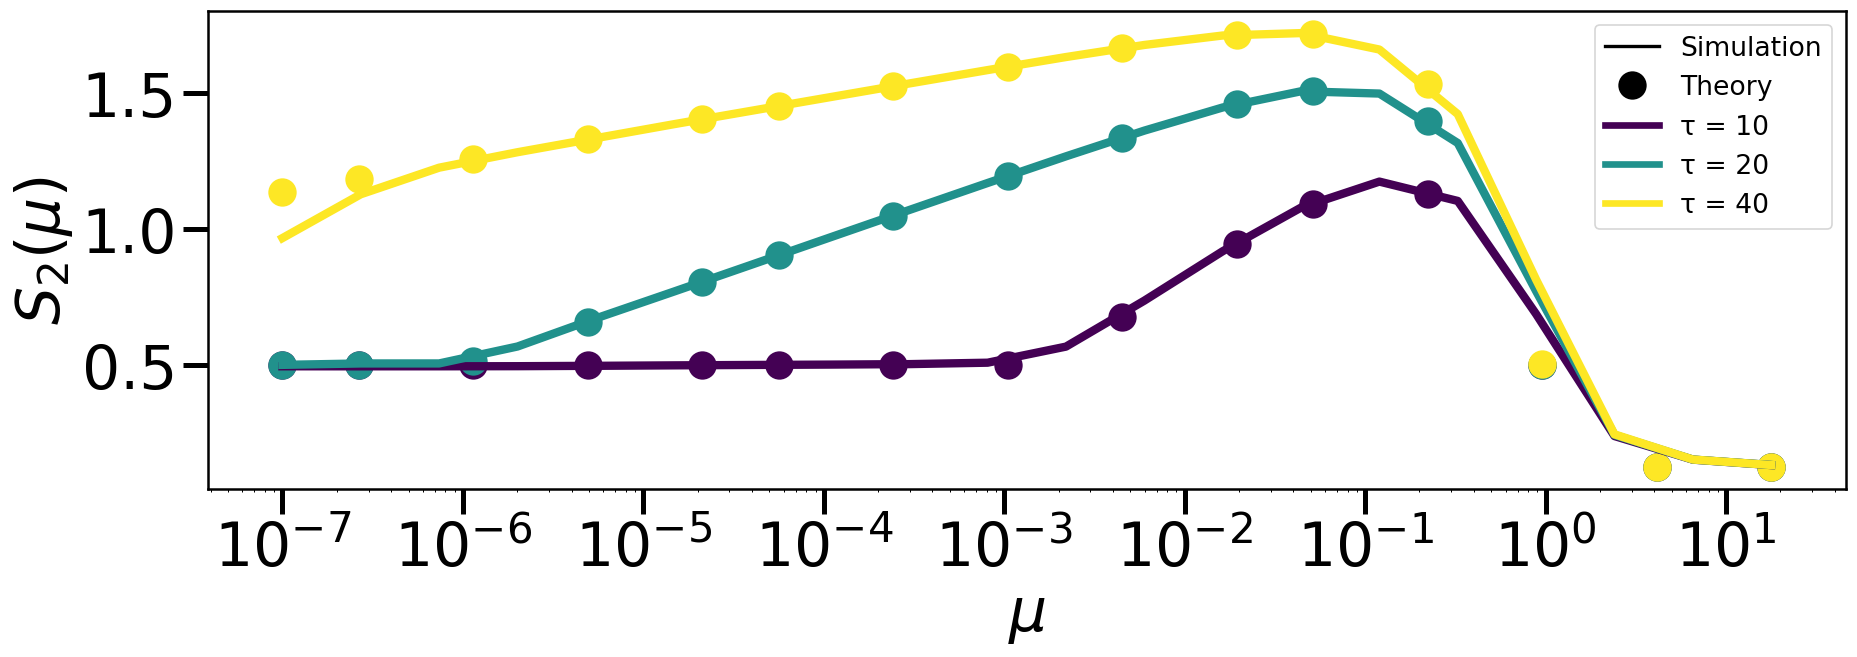

In [10]:
# === Parameters ===
Q = 4
L=2
s=2
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [10, 20, 40]
dt=1e-2
PopSize=10**15
mu_list = np.logspace(-7, 1.25, 40)  # equivalent to ν in your Mathematica code
nu_list=np.logspace(-7,1.25,20)
# === Compute theory curves ===



theory_data = {}
for tau in taus:
    theory_data[tau] = [max(s/Q,s-mu*(Q-1)*L/Q+np.log(math.factorial(L+1)*mu**L/Q**L/s**L)/tau) if mu<1 else max(s/Q**L,s-mu*(Q-1)*L/Q+np.log(mu**L/Q**L/s**L*math.factorial(L+1))/tau) for mu in mu_list]

# === Optional: save to CSV to compare with simulation ===
df_list = []
for tau in taus:
    for mu, r in zip(mu_list, theory_data[tau]):
        df_list.append([tau, mu, r])
df_theory = pd.DataFrame(df_list, columns=["tau", "nu", "rInf"])
df_theory.to_csv("growth_data.csv", index=False)

# === Load simulation results (replace with your own growth_for_nu_list function) ===
# from your previous Monte Carlo simulations
# results_sim = growth_for_nu_list(Q, tau, mu_list, dt, PopSize)

# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    print(tau)
    results = growth_for_nu_list(tau, nu_list, s,dt,
    PopSize,
    steps=100000)  # your stochastic sim
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    idx = np.linspace(0, len(mu_list)-1, min(15, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\mu$")
plt.ylabel(r"$S_2(\mu)$")
plt.xscale("log")
plt.tight_layout()
plt.savefig('Effective_Growth_L2.svg')
plt.show()

## L=4

In [11]:
def compete_4x4x4x4_multinomial(
    tau,  nu,s, dt,
    PopSize=10**8,
    steps=1000
):
    # --- helper lists for decoding/encoding ---
    VR_pairs = [(i, j,k,l) for i in range(4) for j in range(4) for k in range(4) for l in range(4)]  # length 16

    # --- initialize population evenly across 256 TRxVR cells ---
    Pop = np.zeros(256, dtype=np.int64)
    base_each = PopSize // 256
    if base_each > 0:
        Pop[:] = base_each
    leftover = PopSize - Pop.sum()
    # give leftover to cell (0,0)
    if leftover > 0:
        Pop[0] += leftover

    # --- fixed 9-state environment cycle as requested ---
    env_cycle_pairs = [
        (0,0,0,0),(1,1,1,1), (2,2,2,2), (3,3,3,3)
    ]
    # create Hcycle: each H is length-16 vector with additive contribution
    Hcycle = []
    for (E1, E2,E3,E4) in env_cycle_pairs:
        h = np.zeros(256, dtype=float)
        for idx, (x, y,z,a) in enumerate(VR_pairs):
            h[idx] =  s*(1 if x == E1 else 0)*(1 if y == E2 else 0)*(1 if z == E3 else 0)*(1 if a == E4 else 0)
        Hcycle.append(h)

    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    freqVR = []
    AvH = []

    for k in range(steps):
        # ---- environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # ---- SELECTION / REPRODUCTION ----
        # growth factors per VR type
        w = np.exp(H * dt)              # shape (16,)
        weighted = Pop * w[:]    
        total_fit = weighted.sum()
        if total_fit <= 0:
            P_repro = np.ones(256, dtype=float) / 256.0
        else:
            P_repro = weighted / total_fit

        Pop = np.random.multinomial(PopSize, P_repro)

        # ---- VR SWITCHING per TR rules (four cases) ----
        if nu * dt > 0:
            for vr in range(256):
                a, b,c,d = VR_pairs[vr]
                count = Pop[vr]
                if count == 0:
                    continue
                s = np.random.binomial(count, nu * dt)
                if s > 0:
                    Pop[vr] -= s
                    redist = np.random.multinomial(s, [1/4.0] * 4)
                    for x in range(4):
                        target = x * 64 + b*16+c*4+d
                        Pop[target] += redist[x]
                count = Pop[vr]
                if count == 0:
                    continue
                s = np.random.binomial(count, nu * dt)
                if s > 0:
                    Pop[vr] -= s
                    redist = np.random.multinomial(s, [1/4.0] * 4)
                    for y in range(4):
                        target = a * 64 + y*16+c*4+d
                        Pop[target] += redist[y]
                count = Pop[vr]
                if count == 0:
                    continue
                s = np.random.binomial(count, nu * dt)
                if s > 0:
                    Pop[vr] -= s
                    redist = np.random.multinomial(s, [1/4.0] * 4)
                    for z in range(4):
                        target = a *64 + b*16+z*4+d
                        Pop[target] += redist[z]
                count = Pop[vr]
                if count == 0:
                    continue
                s = np.random.binomial(count, nu * dt)
                if s > 0:
                    Pop[vr] -= s
                    redist = np.random.multinomial(s, [1/4.0] * 4)
                    for w in range(4):
                        target = a *64 + b*16+c*4+w
                        Pop[target] += redist[w]

        # ---- statistics ----
        freqVR.append(Pop.astype(float) / PopSize)
        AvH.append(np.sum(Pop * H[ :]) / PopSize)

    # discard initial transAient of 3 environment periods
    cut = 3 * int(tau / dt)
    freqVR = np.array(freqVR)
    AvH = np.array(AvH)
    cut_max=(len(AvH)//int(tau / dt))*int(tau / dt)
    return  np.mean(AvH[cut:cut_max])


In [12]:
# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list( 
    tau, nu_list,s, dt,
    PopSize=10**8,
    steps=1000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_4x4x4x4_multinomial)(tau, nu, s,dt,
    PopSize,
    steps) for nu in nu_list
    )
    return results

10
20
40


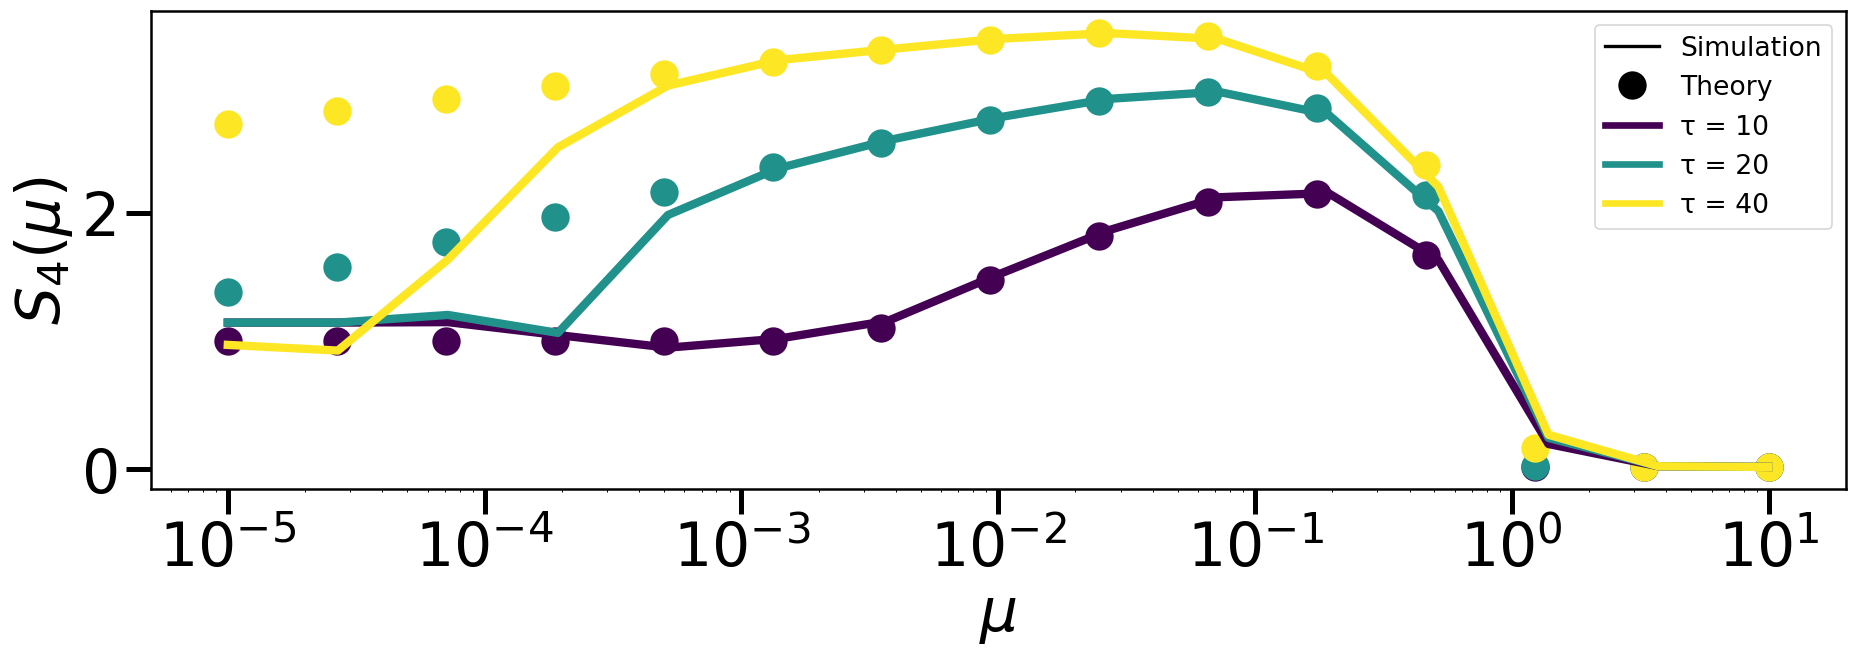

In [13]:
# === Parameters ===
Q = 4
L=4
s=4
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [10,20,40]
dt=5e-2
PopSize=10**14
mu_list = np.logspace(-5, 1, 100)  # equivalent to ν in your Mathematica code
nu_list=np.logspace(-5,1,15)
# === Compute theory curves ===


def Fit_epistasis(tau, mu, Q, L):
    lam = s - (Q-1)*L*mu/Q
    return np.log(mu/Q/s)*L/tau+np.log(math.factorial(L+1))/tau+lam

theory_data = {}
for tau in taus:
    theory_data[tau] = [
    max(Fit_epistasis(tau, mu, Q, L), s/Q) if mu < 1
    else max(Fit_epistasis(tau, mu, Q, L), s/Q**L)
    for mu in mu_list
]

# === Optional: save to CSV to compare with simulation ===
df_list = []
for tau in taus:
    for mu, r in zip(mu_list, theory_data[tau]):
        df_list.append([tau, mu, r])
df_theory = pd.DataFrame(df_list, columns=["tau", "nu", "rInf"])
df_theory.to_csv("growth_data.csv", index=False)

# === Load simulation results (replace with your own growth_for_nu_list function) ===
# from your previous Monte Carlo simulations
# results_sim = growth_for_nu_list(Q, tau, mu_list, dt, PopSize)

# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    print(tau)
    results = growth_for_nu_list(tau, nu_list,s, dt,
    PopSize,
    steps=int(tau/dt*10))  # your stochastic sim
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    idx = np.linspace(0, len(mu_list)-1, min(15, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\mu$")
plt.ylabel(r"$S_4(\mu)$")
plt.xscale("log")
plt.tight_layout()
plt.savefig('Effective_Growth_L4.svg')
plt.show()